# Practical: Identifying Genetic Markers Associated with Crop Traits

**Aim:** Analyze genomic data from crops to identify genetic markers associated with desirable traits, such as disease resistance or yield.

This notebook uses a **synthetic dataset** to:
1. Generate genetic marker data for 500 plants.
2. Explore crop yield.
3. Find markers correlated with yield.
4. Train a Random Forest regression model.
5. Evaluate predictions and identify important markers.

> **Note:** The data is artificially generated for learning. It is not real crop genomic data, and the results do not establish real biological associations.

## 1. Import required libraries

We use NumPy and pandas for data handling, Matplotlib for graphs, and scikit-learn for model training and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Generate a genomic dataset

Each row represents one plant, and each marker column represents a genetic marker.

Marker values 0, 1, and 2 represent the number of copies of a selected allele in this simplified example.

In [2]:
rng = np.random.default_rng(42)

n_plants = 500
n_markers = 100

X = rng.integers(0, 3, size=(n_plants, n_markers))

markers = [f"Marker_{i+1:03d}" for i in range(n_markers)]

# Assign artificial effects to five markers
effects = np.zeros(n_markers)
effects[[5, 18, 37, 64, 82]] = [1.8, -1.4, 1.2, 1.6, -1.0]

# Generate crop yield using marker effects and random noise
yield_value = 50 + X @ effects + rng.normal(0, 2.5, n_plants)

df = pd.DataFrame(X, columns=markers)
df["Yield"] = yield_value

display(df.head())
print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())

display(df["Yield"].describe().to_frame("Yield"))

,Marker_001,Marker_002,Marker_003,Marker_004,Marker_005,Marker_006,Marker_007,Marker_008,Marker_009,Marker_010,...,Marker_092,Marker_093,Marker_094,Marker_095,Marker_096,Marker_097,Marker_098,Marker_099,Marker_100,Yield
0,0,2,1,1,1,2,0,2,0,0,...,2,2,1,2,0,0,2,1,0,52.247304
1,2,0,2,0,2,2,2,1,1,2,...,1,1,1,2,0,1,0,1,2,52.689918
2,1,2,1,2,1,0,2,2,0,2,...,0,2,0,1,1,2,1,0,0,52.334838
3,1,2,0,2,1,0,0,1,0,0,...,0,1,1,2,2,0,0,0,0,45.140410
4,2,2,0,2,1,1,1,0,2,0,...,2,2,1,0,1,0,1,2,1,53.006993


Dataset shape: (500, 101)
Missing values: 0


,Yield
count,500.000000
mean,52.354967
std,3.701099
min,40.779222
25%,49.901240
50%,52.201145
75%,54.970736
max,64.890506


## 3. Visualize crop yield distribution

The histogram shows how yield values are distributed across the plants.

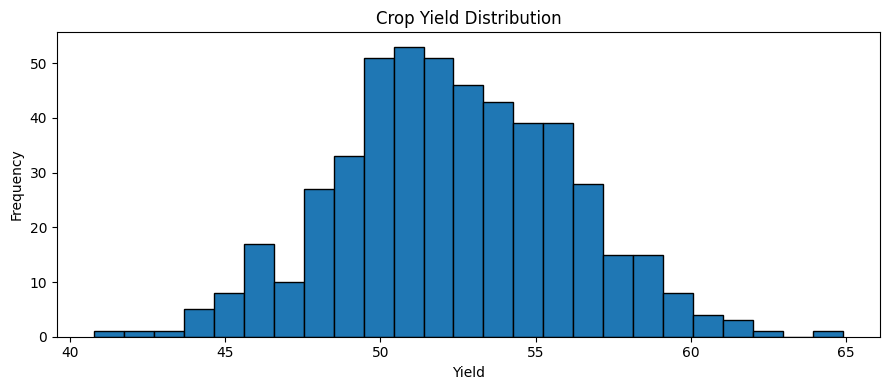

In [3]:
plt.figure(figsize=(9, 4))
plt.hist(df["Yield"], bins=25, edgecolor="black")
plt.title("Crop Yield Distribution")
plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 4. Marker-trait association screening

Calculate the correlation between each genetic marker and crop yield.

Correlation ranges from -1 to +1:
- Positive: marker values and yield tend to increase together.
- Negative: marker values tend to move in opposite directions.
- Near zero: little or no linear relationship.

In [4]:
corr = df[markers].corrwith(df["Yield"])

assoc = pd.DataFrame({
    "Marker": corr.index,
    "Correlation": corr.values,
    "Absolute_Correlation": np.abs(corr.values)
})

assoc = assoc.sort_values("Absolute_Correlation", ascending=False)

display(assoc.head(15))

,Marker,Correlation,Absolute_Correlation
5,Marker_006,0.434544,0.434544
64,Marker_065,0.353566,0.353566
18,Marker_019,-0.304629,0.304629
82,Marker_083,-0.264839,0.264839
37,Marker_038,0.227802,0.227802
30,Marker_031,-0.130347,0.130347
36,Marker_037,-0.111096,0.111096
11,Marker_012,-0.096864,0.096864
33,Marker_034,-0.093227,0.093227
25,Marker_026,-0.090650,0.090650


## 5. Plot the top marker-trait associations

The plot displays the 15 markers with the strongest absolute correlations with yield.

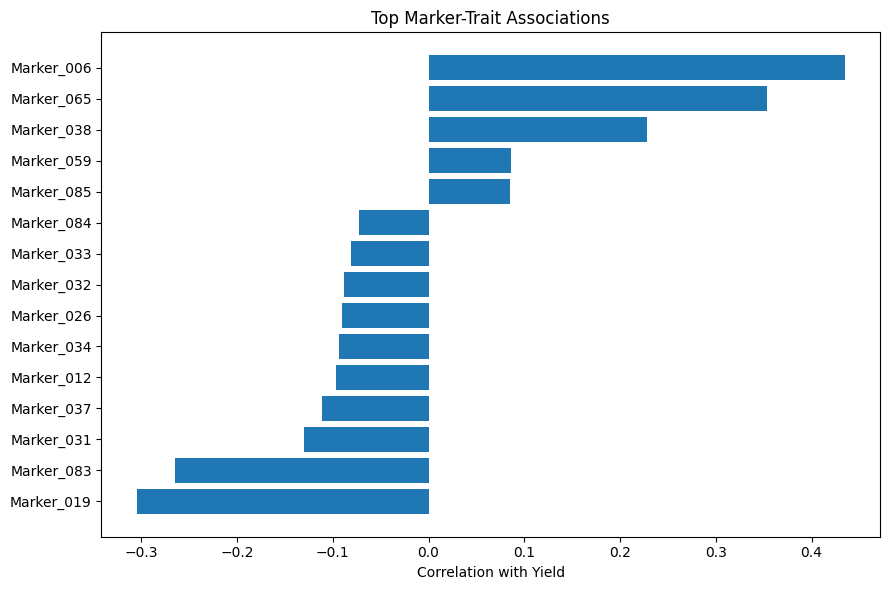

In [5]:
top = assoc.head(15).sort_values("Correlation")

plt.figure(figsize=(9, 6))
plt.barh(top["Marker"], top["Correlation"])
plt.title("Top Marker-Trait Associations")
plt.xlabel("Correlation with Yield")
plt.tight_layout()
plt.show()

## 6. Split data into training and testing sets

Use 80% of the plants to train the model and 20% to evaluate it on unseen plants.

In [6]:
X = df[markers]
y = df["Yield"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 400
Testing samples: 100


## 7. Train a Random Forest Regression model

Random Forest combines multiple decision trees. Here, it learns to predict numerical crop yield from genetic marker values.

In [7]:
model = RandomForestRegressor(
    n_estimators=300,
    max_features="sqrt",
    random_state=42
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

print("First 10 predictions:")
print(pred[:10])

First 10 predictions:
[53.56555869 52.5664071  51.72654124 53.96460388 50.75467938 51.9439322
 51.61541128 53.76799128 52.11699121 50.61994395]


## 8. Evaluate model performance

- **MAE:** Average absolute prediction error.
- **RMSE:** Prediction error that penalizes larger errors more strongly.
- **R²:** Measures how much variation in yield is explained by the model. A value closer to 1 generally indicates a better fit.

In [8]:
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")

MAE: 2.5312
RMSE: 3.1422
R²: 0.2592


## 9. Identify important genetic markers

Random Forest feature importance ranks markers by how much they contribute to the model's predictions.

A high importance score is not proof that a marker causes higher yield or is statistically significant.

In [9]:
importance = pd.Series(
    model.feature_importances_,
    index=markers
).sort_values(ascending=False)

display(importance.head(15).to_frame("Importance"))

,Importance
Marker_006,0.062242
Marker_065,0.043997
Marker_019,0.036109
Marker_083,0.030373
Marker_038,0.023805
Marker_084,0.013105
Marker_031,0.012173
Marker_012,0.012172
Marker_034,0.011216
Marker_037,0.010063


## 10. Visualize important markers

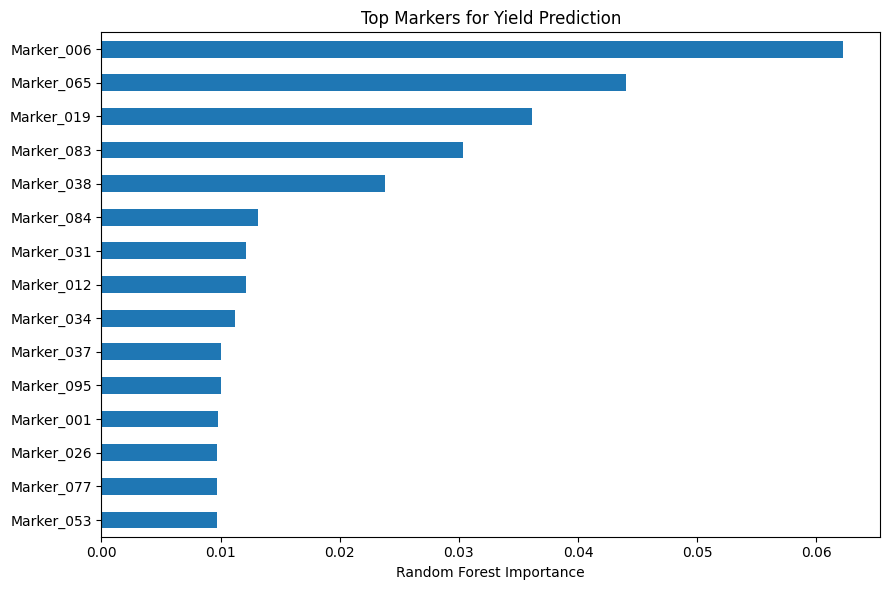

In [10]:
importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top Markers for Yield Prediction")
plt.xlabel("Random Forest Importance")
plt.tight_layout()
plt.show()

## 11. Compare observed and predicted crop yield

Each dot represents one plant. The dashed diagonal line represents perfect prediction. Points closer to the line indicate more accurate predictions.

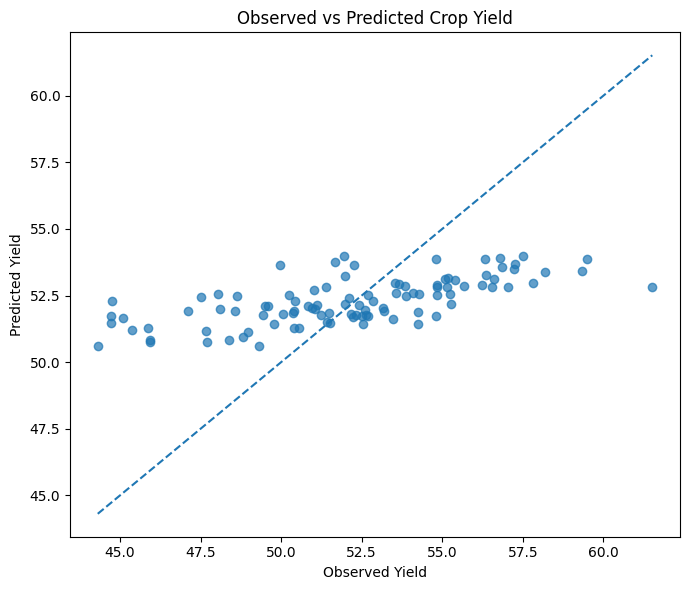

In [11]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred, alpha=0.7)

lo = min(y_test.min(), pred.min())
hi = max(y_test.max(), pred.max())

plt.plot([lo, hi], [lo, hi], "--")

plt.title("Observed vs Predicted Crop Yield")
plt.xlabel("Observed Yield")
plt.ylabel("Predicted Yield")
plt.tight_layout()
plt.show()

## 12. Conclusion

In this practical, we generated a synthetic crop genomic dataset and explored relationships between genetic markers and yield. We used correlation to screen for potentially associated markers, trained a Random Forest regression model to predict yield, evaluated its performance using MAE, RMSE, and R², and ranked markers using feature importance.

**Limitation:** These are simulated results. Real crop marker-trait studies require real genotyping and trait measurements, appropriate statistical association testing, and validation across relevant plant populations and environments.